In [1]:
import pandas as pd
import torch
import os
import re

import pyprobound
import pyprobound.plotting
import pyprobound.fitting

findfont: Font family ['Arial'] not found. Falling back to DejaVu Sans.


In [2]:
directory = 'countTables'
cts = [f for f in os.listdir(directory)]
# Remove the '_CT.tsv' pattern from the filenames
ids = [re.sub('.tsv', '', f) for f in cts]

In [3]:
ids

['AbdA',
 'AbdB',
 'AntHOX1a_intein_PBX',
 'AntHOX8PBXL5',
 'Antp',
 'Dfd',
 'HOX1_PBX',
 'HOX6a_PBX',
 'HOX7_PBX',
 'Lab',
 'Pb',
 'Scr',
 'Ubx']

/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:147: UserWarning: Output file pyPBtemp/AbdA.txt is not empty
  warnings.warn(f"Output file {output} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:149: UserWarning: Checkpoint file pyPBtemp/AbdA.pt is not empty
  warnings.warn(f"Checkpoint file {checkpoint} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
findfont: Font family ['Helvetica'] not found. Falling back to DejaVu Sans.


tensor(0.9440) tensor(0.0086) tensor(0.9526)
AbdA


/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:147: UserWarning: Output file pyPBtemp/AbdB.txt is not empty
  warnings.warn(f"Output file {output} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:149: UserWarning: Checkpoint file pyPBtemp/AbdB.pt is not empty
  warnings.warn(f"Checkpoint file {checkpoint} is not empty")


tensor(1.0544) tensor(0.0083) tensor(1.0627)
AbdB


/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:147: UserWarning: Output file pyPBtemp/AntHOX1a_intein_PBX.txt is not empty
  warnings.warn(f"Output file {output} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:149: UserWarning: Checkpoint file pyPBtemp/AntHOX1a_intein_PBX.pt is not empty
  warnings.warn(f"Checkpoint file {checkpoint} is not empty")


tensor(0.4769) tensor(0.0181) tensor(0.4950)
AntHOX1a_intein_PBX


... (16 outputs left out)

/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:147: UserWarning: Output file pyPBtemp/Scr.txt is not empty
  warnings.warn(f"Output file {output} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:149: UserWarning: Checkpoint file pyPBtemp/Scr.pt is not empty
  warnings.warn(f"Checkpoint file {checkpoint} is not empty")


tensor(1.0776) tensor(0.0077) tensor(1.0852)
Scr


/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:147: UserWarning: Output file pyPBtemp/Ubx.txt is not empty
  warnings.warn(f"Output file {output} is not empty")
/mnt/e/desktop/test.github.io/PyProBound/venv/lib/python3.10/site-packages/pyprobound/optimizer.py:149: UserWarning: Checkpoint file pyPBtemp/Ubx.pt is not empty
  warnings.warn(f"Checkpoint file {checkpoint} is not empty")


tensor(0.8823) tensor(0.0080) tensor(0.8904)
Ubx


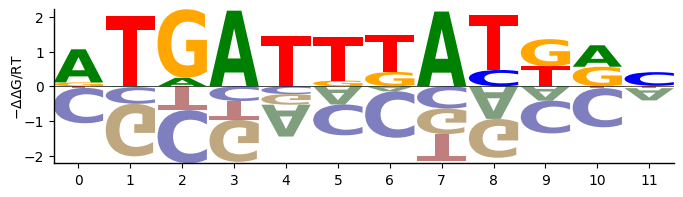

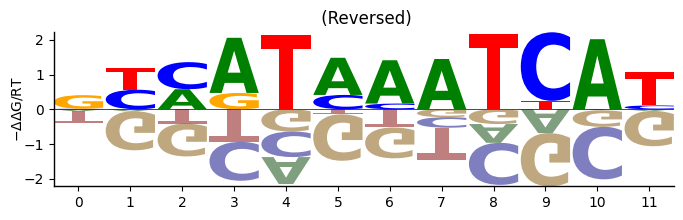

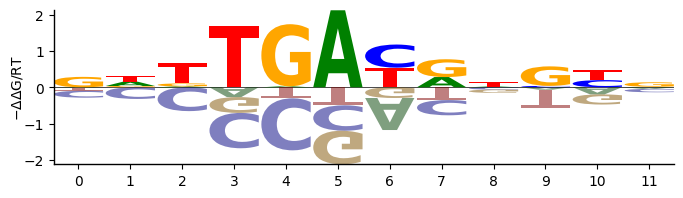

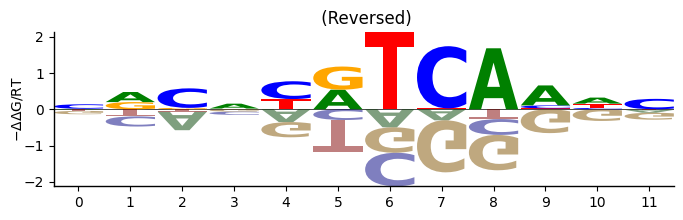

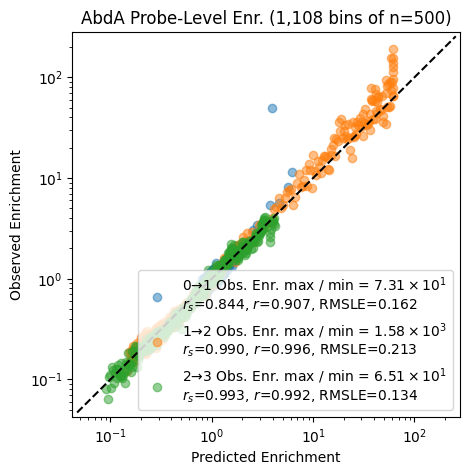

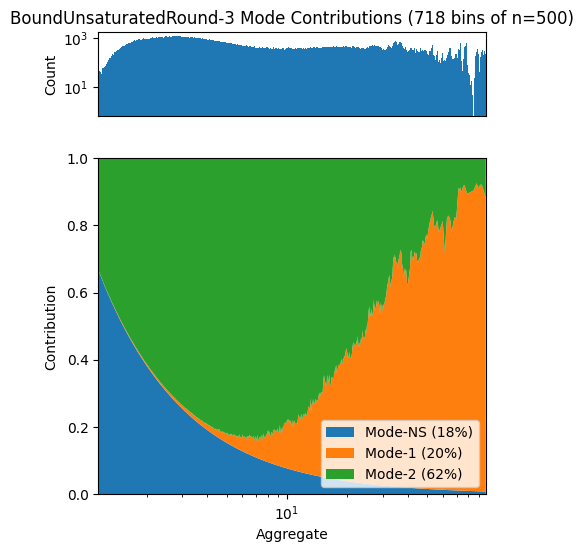

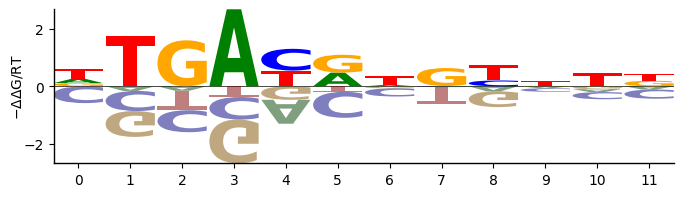

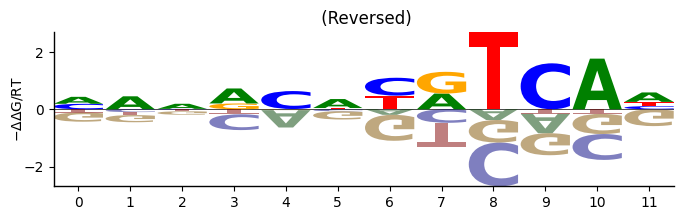

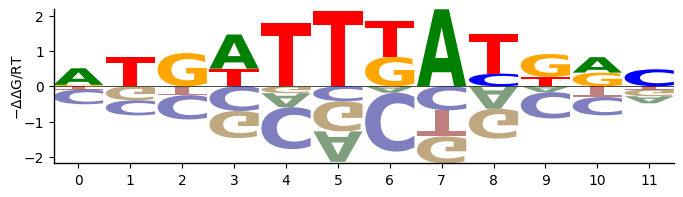

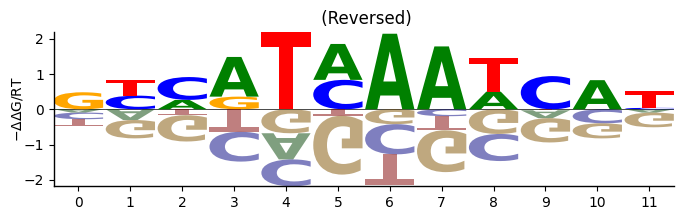

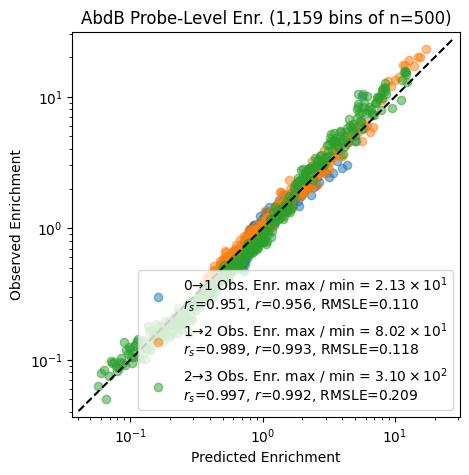

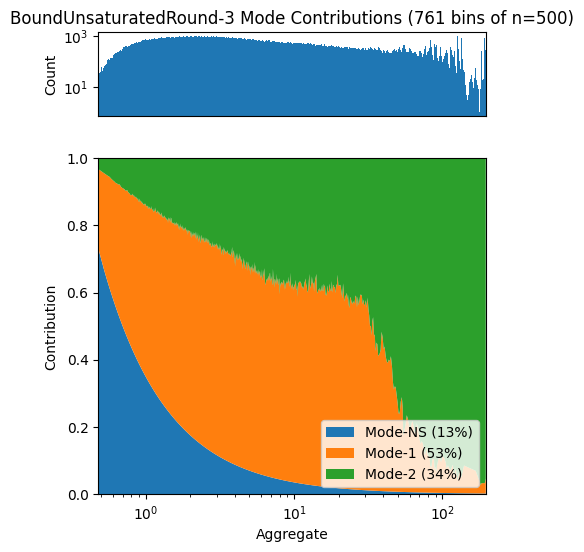

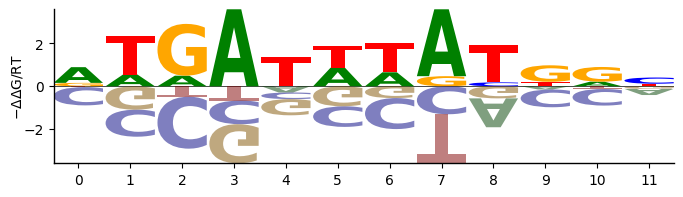

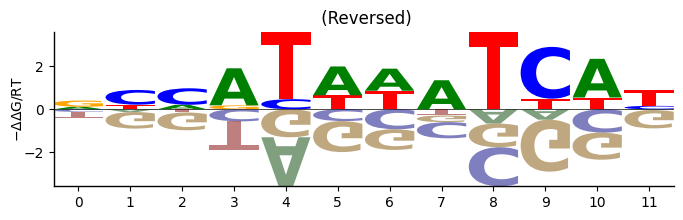

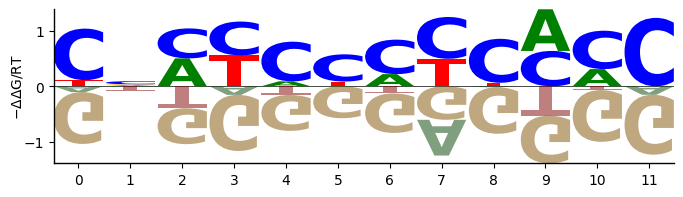

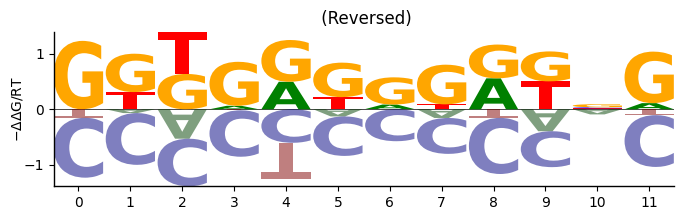

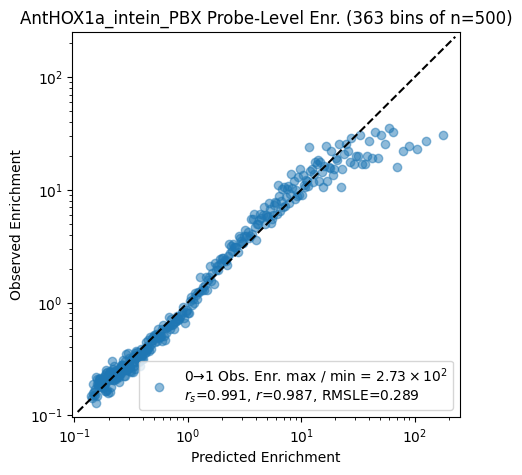

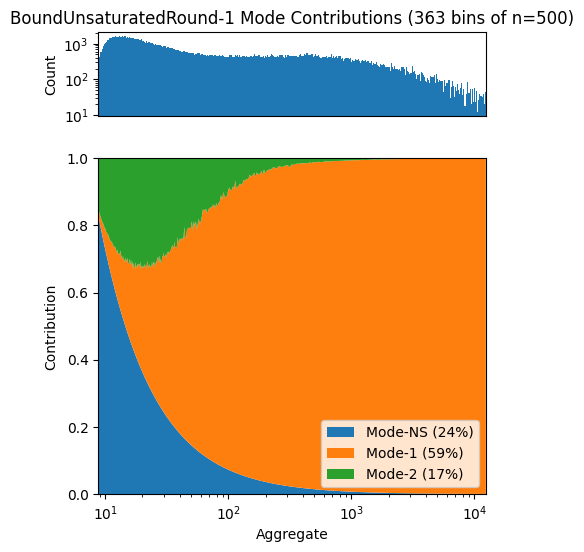

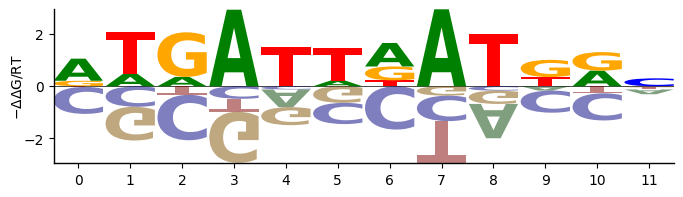

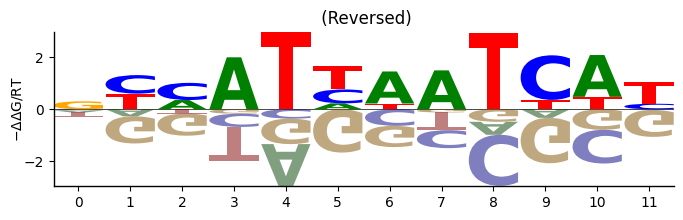

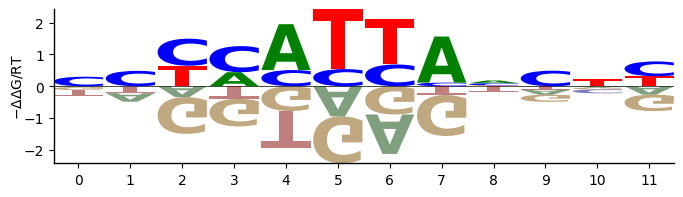

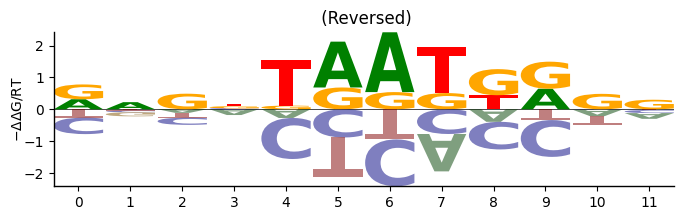

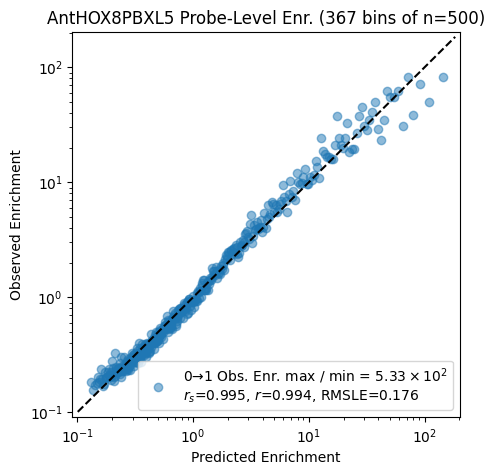

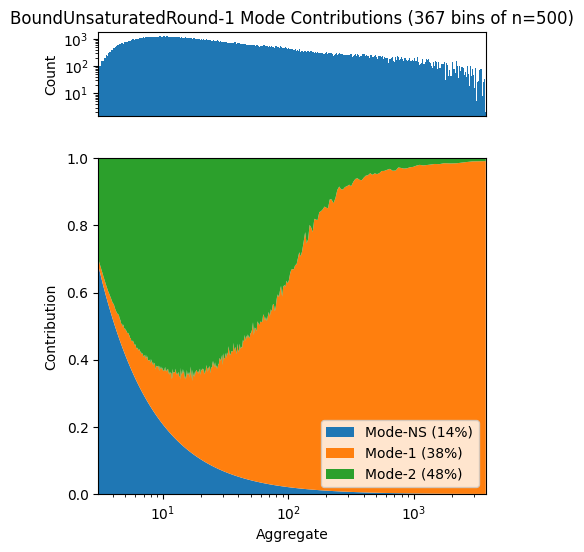

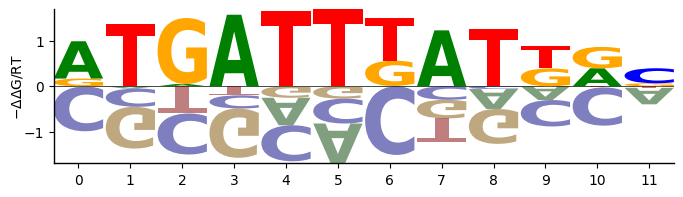

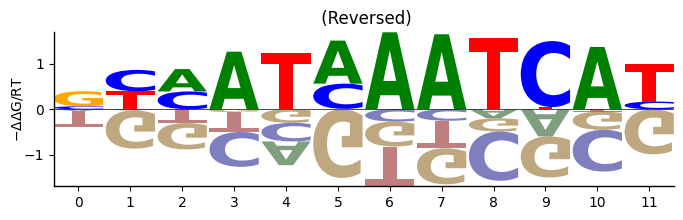

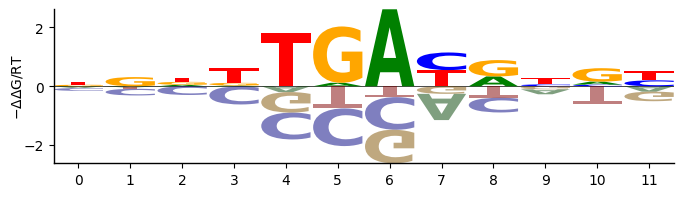

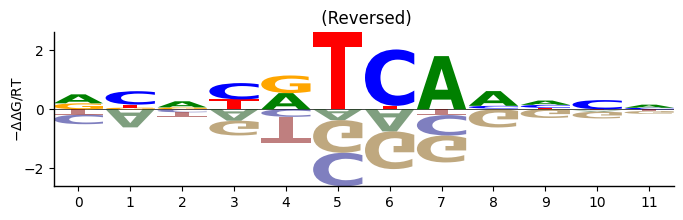

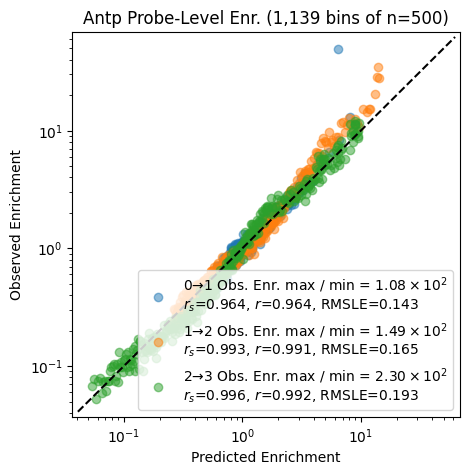

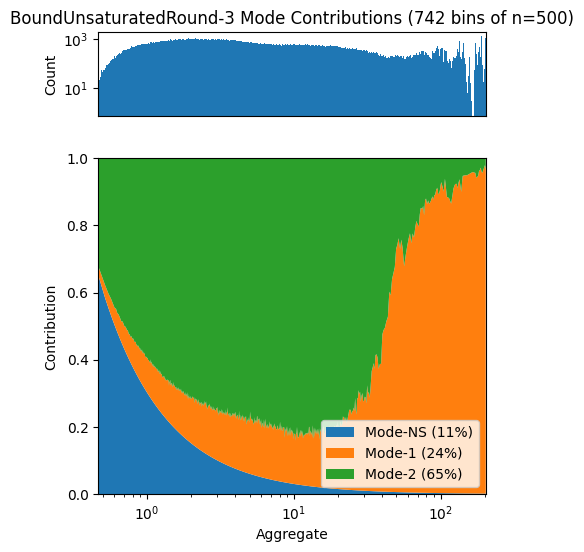

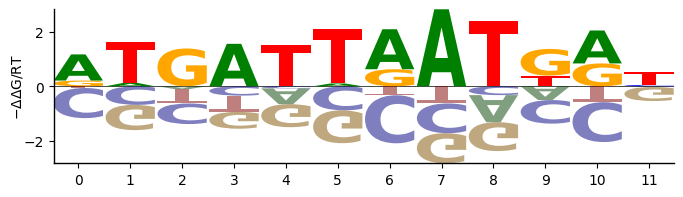

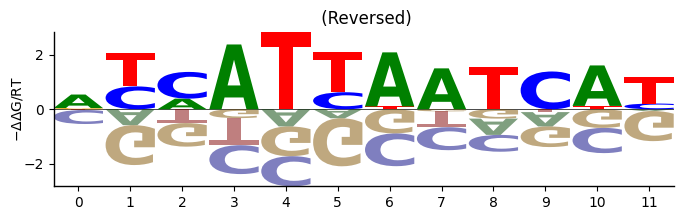

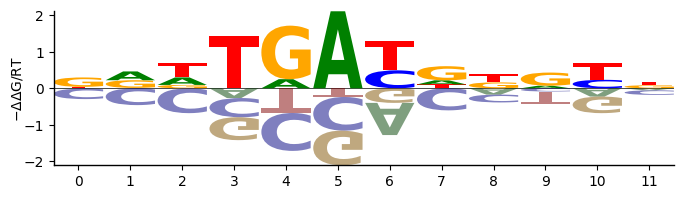

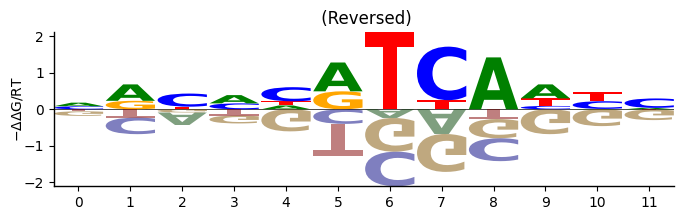

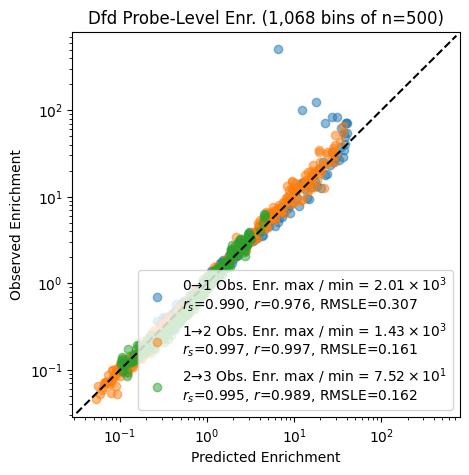

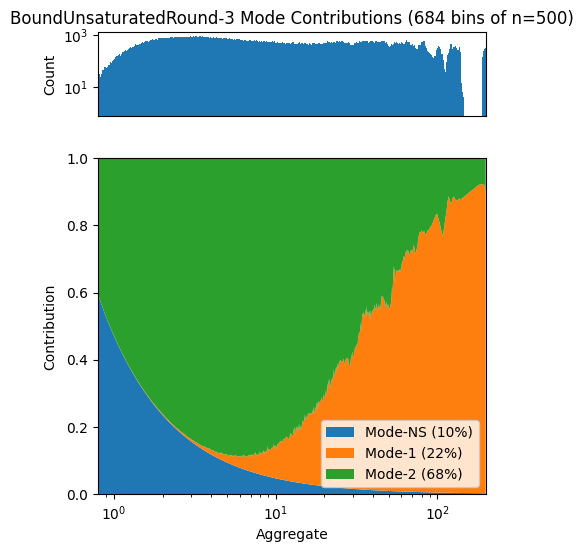

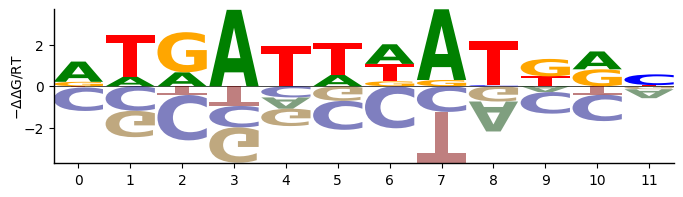

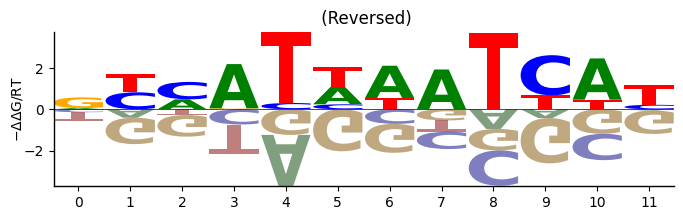

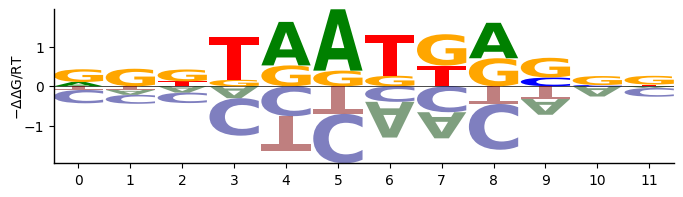

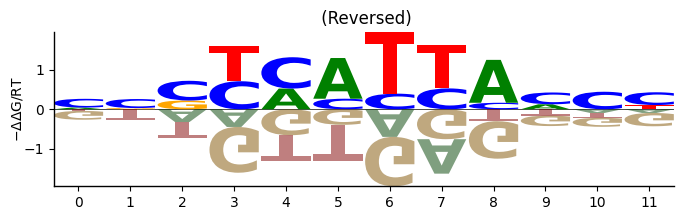

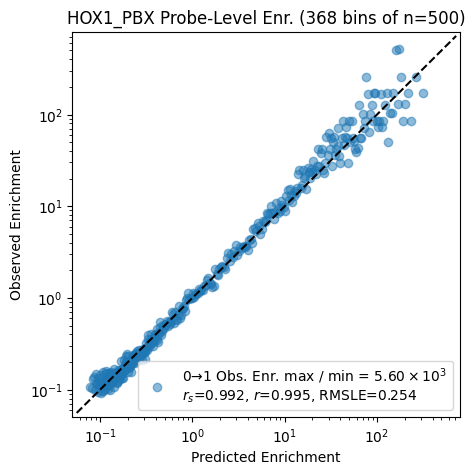

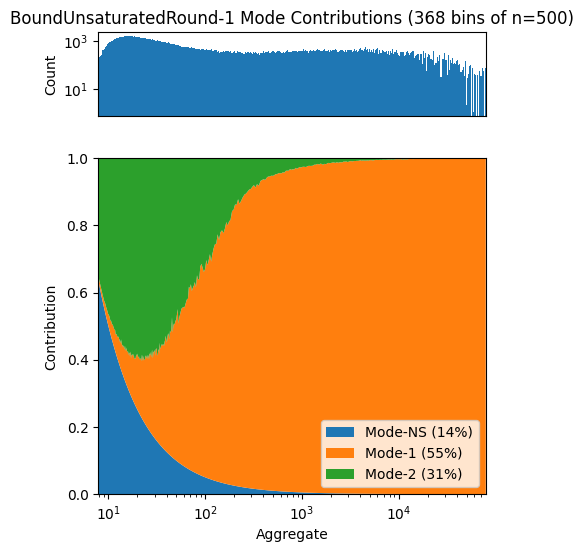

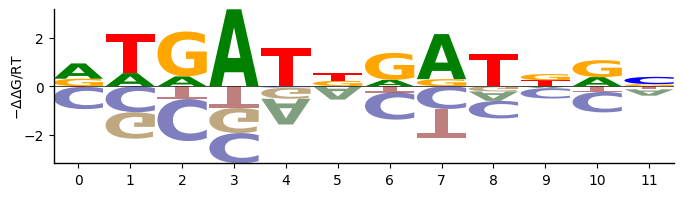

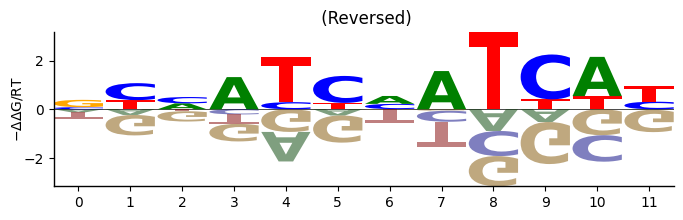

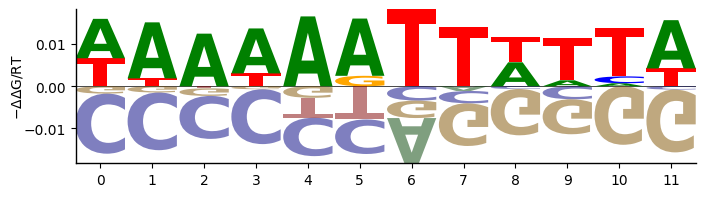

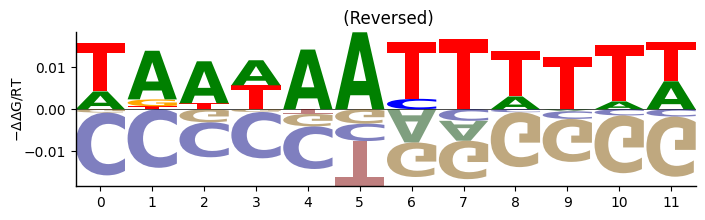

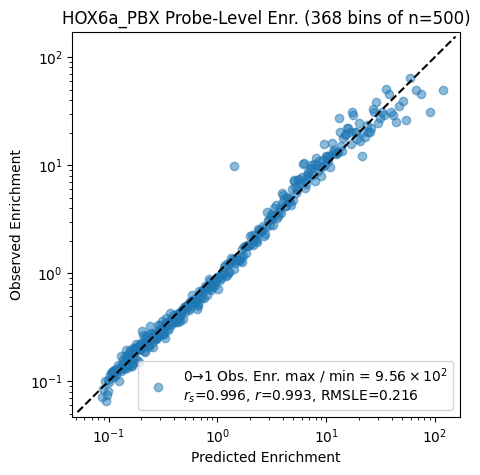

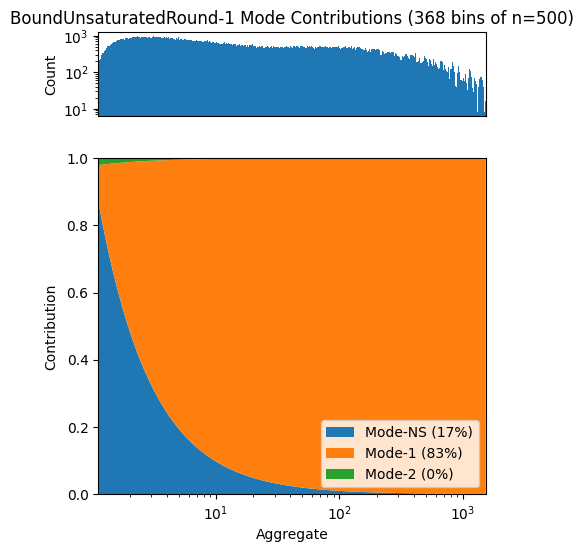

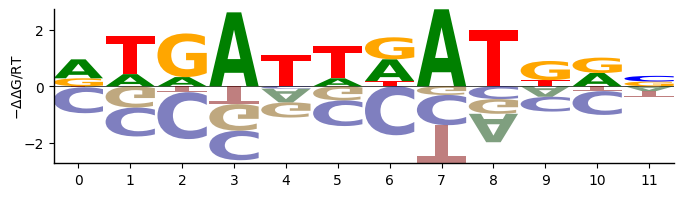

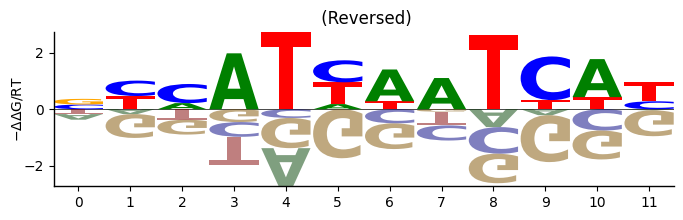

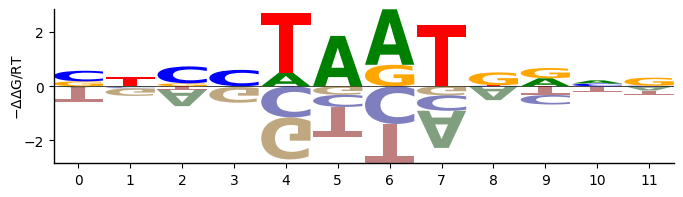

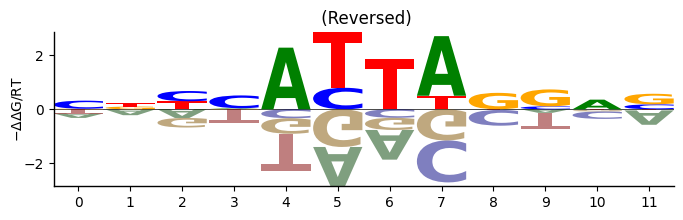

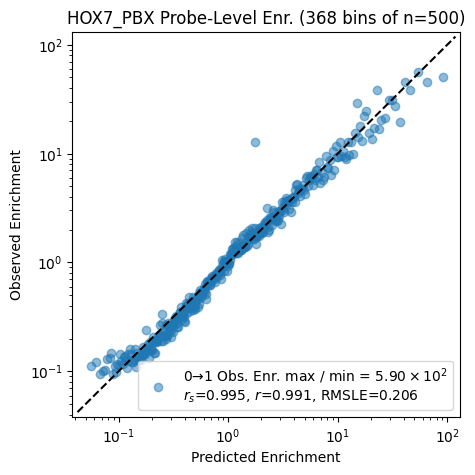

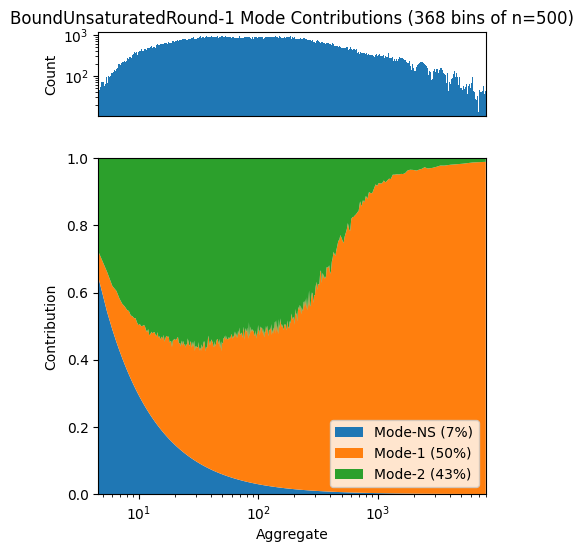

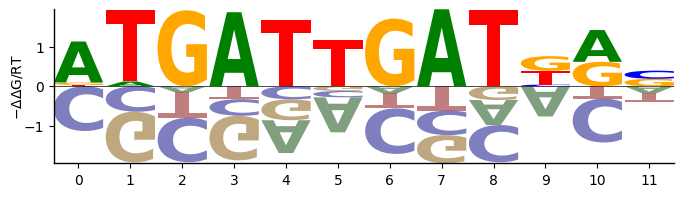

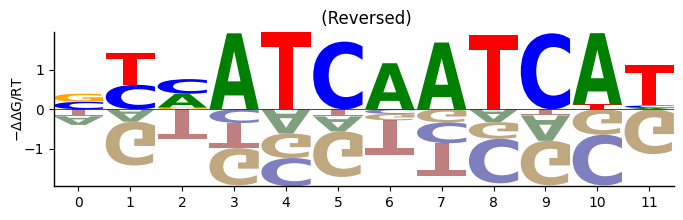

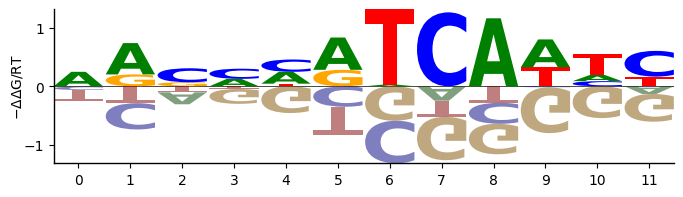

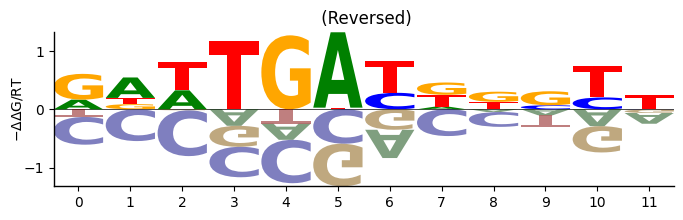

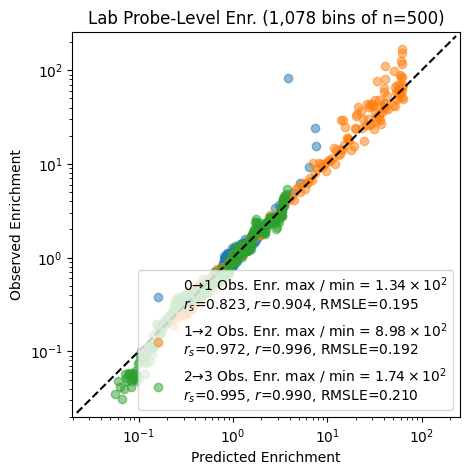

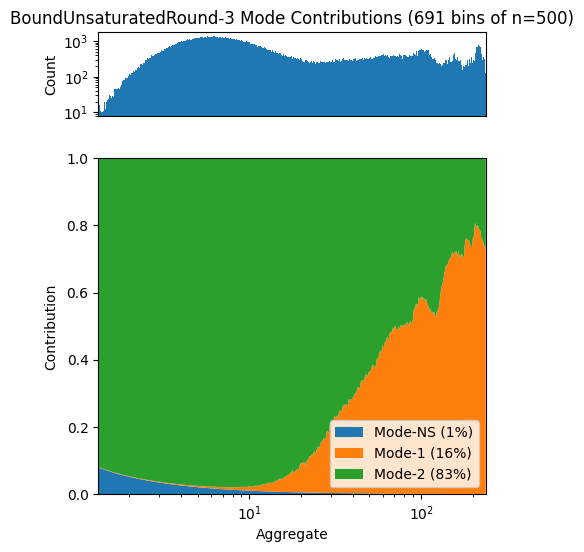

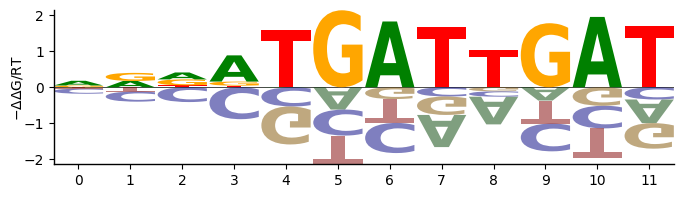

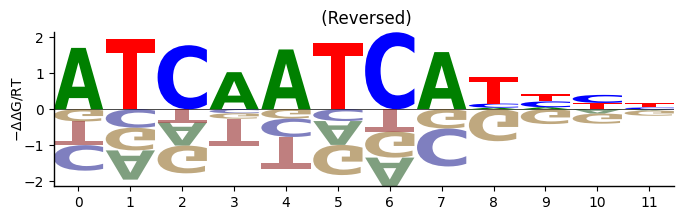

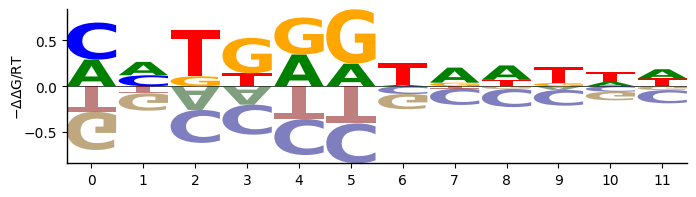

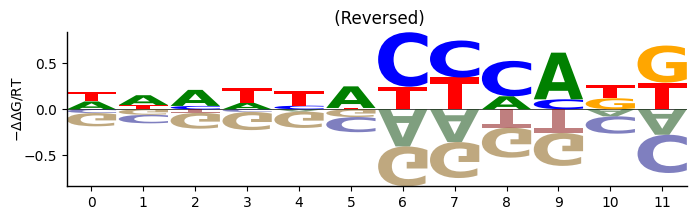

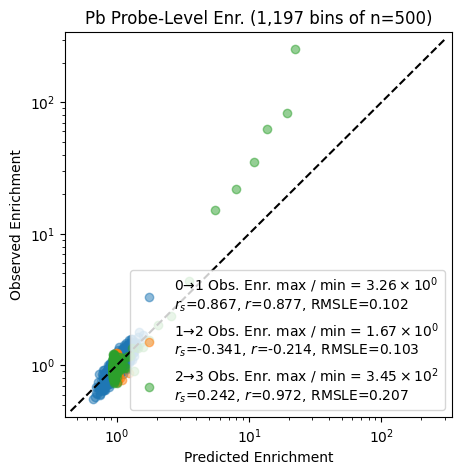

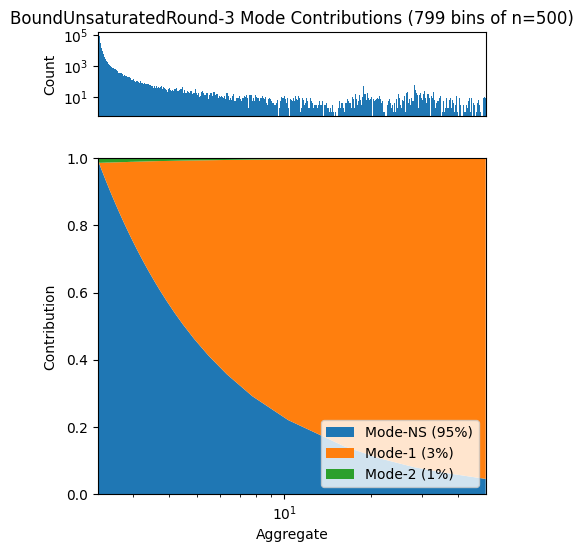

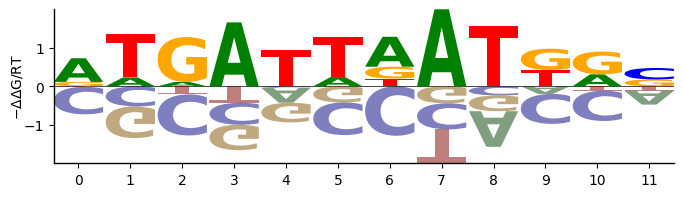

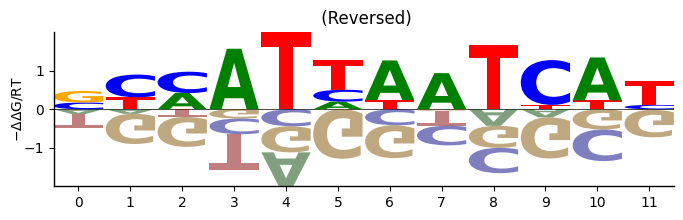

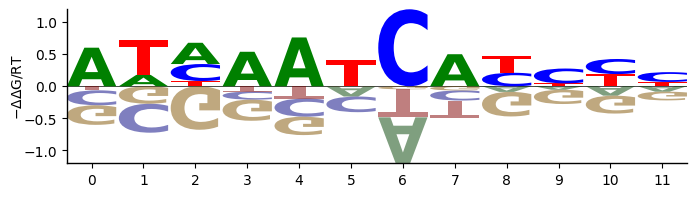

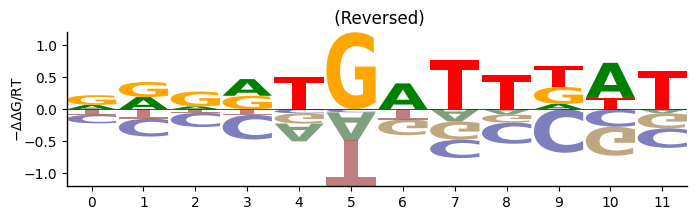

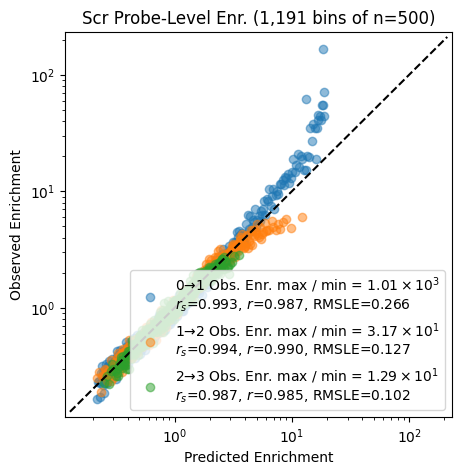

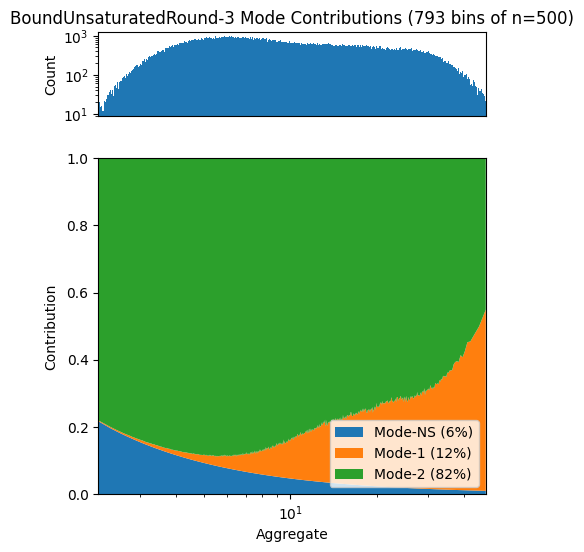

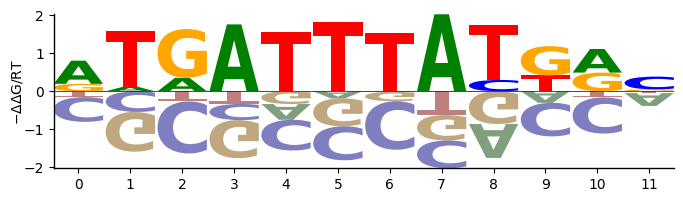

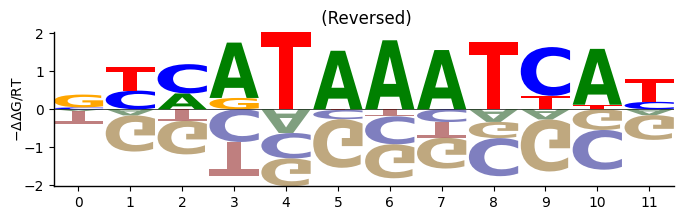

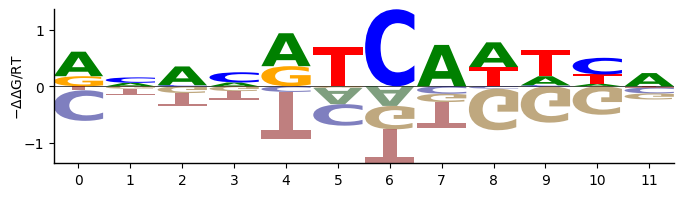

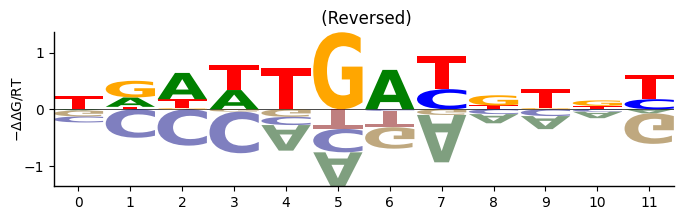

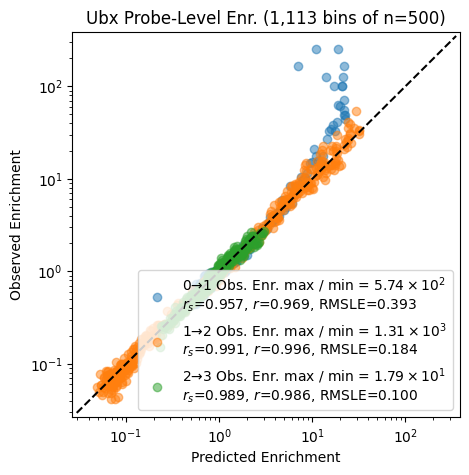

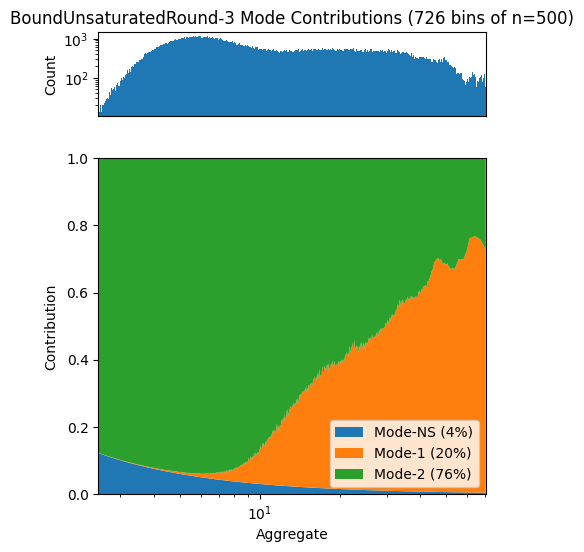

In [ ]:
from pathlib import Path
import pandas as pd
import pyprobound
import torch

outdir = Path.cwd() / "pyPBtemp"
outdir.mkdir(parents=True, exist_ok=True)

# Assuming 'ids' and 'directory' are defined elsewhere in your script
for id in ids:
    alphabet = pyprobound.alphabets.DNA()
    dataframe = pd.read_csv(
        f"{directory}/{id}.tsv", header=0, index_col=0, sep="\t"
    )
    
    # Create the count table
    count_table = pyprobound.CountTable(
        dataframe,
        alphabet,
        left_flank="CCGACCTGG",
        right_flank="CCAGG",
        left_flank_length=5,
        right_flank_length=5,
    )
    
    nonspecific = pyprobound.layers.NonSpecific(alphabet=alphabet, name="NS")
    psams = [
        pyprobound.layers.PSAM(
            kernel_size=12,
            alphabet=alphabet,
            seed=["TTGATTDATNNN"],
            seed_scale=40,
            
        ),
        pyprobound.layers.PSAM(
            kernel_size=12,
            alphabet=alphabet,
            increment_flank=True,
            shift_footprint_heuristic=True,
            increment_footprint=True,
            increment_flank_with_footprint=True,
        ),
    ]
    
    # Modes are shared across all rounds
    modes = [
        pyprobound.Mode.from_nonspecific(nonspecific, count_table)
    ] + [
        pyprobound.Mode.from_psam(psam, count_table)
        for psam in psams
    ]
    
    # --- MULTI-ROUND MODIFICATION START ---
    
    # 1. create the initial round (Round 0)
    rounds = [pyprobound.rounds.InitialRound()]

    # 2. Get the total number of rounds (columns) from the count table
    # counts_per_round shape is (n_sequences, n_rounds)
    n_rounds = dataframe.shape[1]

    # 3. Loop to create subsequent rounds, chaining them together
    # We range from 1 to n_rounds because Round 0 is already created
    for i in range(1, n_rounds):
        # The new round takes the previous round (rounds[-1]) as input
        new_round = pyprobound.rounds.BoundUnsaturatedRound.from_binding(
            modes, 
            rounds[-1], 
            activity_heuristic=0.4
        )
        rounds.append(new_round)

    experiment = pyprobound.Experiment(
        rounds,  # Pass the full list of chained rounds
        name=f"{id}",
        counts_per_round=count_table.counts_per_round,
    )
    
    # --- MULTI-ROUND MODIFICATION END ---
    
    model = pyprobound.MultiExperimentLoss([experiment], pseudocount=20)
    
    optimizer = pyprobound.Optimizer(
        model,
        [count_table],
        greedy_threshold=2e-4,
        device="cpu",
        checkpoint=f"pyPBtemp/{id}.pt",
        output=f"pyPBtemp/{id}.txt",
    )
    
    optimizer.train_sequential()
    
    optimizer.reload()
    with torch.inference_mode():
        loss, reg = model([count_table])
        print(loss, reg, loss + reg)

    print(f"{id}")
    
    # Cleaned up the loop using enumerate
    for i, psam in enumerate(psams):
        pyprobound.plotting.logo(psam)
        pyprobound.plotting.logo(psam, reverse=True)

        data = psam.get_filter(0)[0]
        table_str = '\n'.join(['\t'.join([f'{item:.4f}' for item in row]) for row in data])
        with open(f'{id}_12merPSAM_{i}.txt', 'w') as file:
            file.write(table_str)
        
    pyprobound.plotting.probe_enrichment(experiment, count_table, kernel=500)
    
    # Plot contribution for the final round (usually the most informative)
    pyprobound.plotting.contribution(rounds[-1], count_table)